# 반복실험: AK-MCS-U vs NH-AK-MCS-U
`runs/repeated_01/rep_XXX/{reference,nh}`를 읽어 **완료된 paired 반복**을 분석합니다. 아래 `EXPERIMENT_DIR`를 변경하면 다른 실험을 분석할 수 있습니다.

같은 학습 g 호출 수에서 실제 고장확률 오차, 영역 오분류, 고장 누락률, 평균 Phi(-U)를 비교합니다. 표는 평균·표준편차·분산·중앙값을, 곡선의 띠는 **seed 간 ±1 표본 표준편차**를 보여줍니다. 각 체크포인트는 두 방법 모두 해당 호출 수까지 기록된 반복만 포함하고, 최종 비교는 분석 가능한 가장 큰 호출 수에서 수행합니다. 반복별 NH − Reference 차이가 음수이면 NH의 오류가 작습니다.

부분 완료 반복은 통계에서 제외하고 상태를 표시합니다. 실행 중 결과는 완료된 반복에 조건부인 잠정 결과입니다. summary.json을 완료 표식으로 사용하며, 숨겨진 interrupted 폴더와 오래된 results.json에는 의존하지 않습니다.


In [73]:
from pathlib import Path
import hashlib
import html
import json
import math
import sys
import time

import numpy as np
import scipy
import matplotlib.pyplot as plt
from scipy.special import ndtr
from scipy.stats import norm, t
from IPython.display import HTML, SVG, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pipeline.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from g import Problem
from metamodels.ordinary_kriging import OrdinaryKriging

EXPERIMENT_DIR = ROOT / "runs/AK-MCS-EFF"
N_TEST = 60_000
N_REFERENCE = 1_000_000
TEST_SEED = 2026101801
REFERENCE_SEED = 2026101802
CALL_STEP = 100
RECOMPUTE = False
CACHE_VERSION = 2
ARTIFACT_DIR = ROOT / "artifacts/analyze" / EXPERIMENT_DIR.name
MODES = {"reference": "AK-MCS-U", "nh": "NH-AK-MCS-U"}
COLORS = {"reference": "#2563eb", "nh": "#e87924"}
assert min(N_TEST, N_REFERENCE, CALL_STEP) > 0 and TEST_SEED != REFERENCE_SEED
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

def read_jsonl(path):
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def show_html(markup):
    if display is None:
        print(html.unescape(markup.replace("<tr>", "\n").replace("</td>", "  ").replace("<th>", "  ").replace("</th>", "  ").replace("</tr>", "").replace("<table>", "").replace("</table>", "")))
    else:
        display(HTML(markup))

def table(headers, rows):
    def cell(value):
        return html.escape(str(value))
    head = "".join(f"<th style='text-align:left;padding:5px 12px;border-bottom:1px solid #aaa'>{cell(v)}</th>" for v in headers)
    body = "".join("<tr>" + "".join(f"<td style='padding:4px 12px'>{cell(v)}</td>" for v in row) + "</tr>" for row in rows)
    show_html(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>")

def fmt(value, digits=5):
    if value is None:
        return "—"
    if isinstance(value, bool):
        return str(value)
    if isinstance(value, (float, int)):
        return f"{value:.{digits}f}"
    return str(value)


def pct(value):
    return "—" if value is None else f"{100*value:.4f}%"

def save_json(path, value):
    temporary = path.with_suffix(".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")
    temporary.replace(path)

def summarize(values):
    values = np.asarray([v for v in values if v is not None and math.isfinite(v)], float)
    n = len(values)
    return {"n": n, "mean": float(values.mean()) if n else None,
            "sd": float(values.std(ddof=1)) if n > 1 else None,
            "variance": float(values.var(ddof=1)) if n > 1 else None,
            "median": float(np.median(values)) if n else None}

assert summarize([1, 3]) == {"n": 2, "mean": 2., "sd": np.sqrt(2), "variance": 2., "median": 2.}
assert summarize([1])["sd"] is None and summarize([])["mean"] is None


In [74]:
if not EXPERIMENT_DIR.is_dir():
    raise FileNotFoundError(EXPERIMENT_DIR)
pairs, status_rows = {}, []
for folder in sorted(EXPERIMENT_DIR.glob("rep_*")):
    if not folder.is_dir() or not folder.name.removeprefix("rep_").isdigit():
        continue
    complete = {mode: (folder/mode/"summary.json").is_file() for mode in MODES}
    status_rows.append((folder.name, *["완료" if complete[m] else "미완료/없음" for m in MODES],
                        "집계" if all(complete.values()) else "제외"))
    if not all(complete.values()):
        continue
    pair = {}
    for mode in MODES:
        d = folder/mode
        run = {key: read_json(d/name) for key, name in
               (("config", "effective_config.json"), ("summary", "summary.json"), ("initial", "initial_design.json"))}
        run.update(folder=d, calls=read_jsonl(d/"g_calls.jsonl"),
                   evaluations=read_jsonl(d/"evaluation.jsonl"),
                   samples_hash=sha256(d/"fixed_samples.json"))
        n = run["summary"]["n_true_calls"]
        assert len(run["calls"]) == n == run["summary"]["final"]["n_true_calls"], d
        assert all(c["status"] == "ok" and c["cumulative_calls"] == i+1 for i,c in enumerate(run["calls"])), d
        assert run["evaluations"][-1]["n_true_calls"] == n, d
        assert run["config"]["problem"]["factory"] == "g:Problem"
        assert run["config"]["metamodel"]["factory"] == "metamodels.ordinary_kriging:OrdinaryKriging"
        run["by_call"] = {r["n_true_calls"]: r for r in run["evaluations"]}
        run["fingerprints"] = {name: sha256(d/name) for name in
                               ("effective_config.json", "evaluation.jsonl", "g_calls.jsonl", "initial_design.json")}
        pair[mode] = run
    a, b = pair["reference"], pair["nh"]
    assert {k:v for k,v in a["config"].items() if k != "mode"} == {k:v for k,v in b["config"].items() if k != "mode"}, folder
    assert a["initial"]["X"] == b["initial"]["X"] and a["initial"]["Y"] == b["initial"]["Y"], folder
    assert a["samples_hash"] == b["samples_hash"], folder
    pairs[folder.name] = pair

table(["반복", "Reference", "NH", "통계 포함"], status_rows)
print(f"발견한 반복 {len(status_rows)}개 중 완료된 paired 반복 {len(pairs)}개.")
checkpoints = []
if pairs:
    first_pair = next(iter(pairs.values()))
    problem_config = first_pair["reference"]["config"]["problem"]
    seeds = [pair["reference"]["config"]["seed"] for pair in pairs.values()]
    assert len(seeds) == len(set(seeds)), "반복 간 seed 중복"
    def comparable_config(cfg):
        cfg = json.loads(json.dumps(cfg))
        for key in ("seed", "mode", "output", "repetitions"):
            cfg.pop(key, None)
        cfg["initial_design"].pop("seed", None)
        cfg["metamodel"].pop("seed", None)
        return cfg
    baseline = comparable_config(first_pair["reference"]["config"])
    for pair in pairs.values():
        assert comparable_config(pair["reference"]["config"]) == baseline, "반복 간 실험 조건이 다릅니다."
    shared_by_pair = {rep: set(pair["reference"]["by_call"]) & set(pair["nh"]["by_call"])
                      for rep, pair in pairs.items()}
    shared = set.union(*shared_by_pair.values())
    checkpoints = sorted({min(shared), max(shared)} | {n for n in shared if n % CALL_STEP == 0})
    print("비교 체크포인트 및 paired 반복 수:")
    for n in checkpoints:
        eligible = [rep for rep, calls in shared_by_pair.items() if n in calls]
        omitted = sorted(set(pairs) - set(eligible))
        print(f"  {n} calls: {len(eligible)}/{len(pairs)} pairs" +
              (f"; 제외: {', '.join(omitted)}" if omitted else ""))
    if first_pair["reference"]["config"]["initial_design"].get("input_file"):
        print("초기 설계는 input_file로 고정되어 있습니다. 반복 변동은 초기 설계 변동을 포함하지 않습니다.")
else:
    print("완료된 paired 반복이 없어 분석을 대기합니다. 완료 후 전체 셀을 다시 실행하세요.")


반복,Reference,NH,통계 포함
rep_001,완료,완료,집계
rep_002,완료,완료,집계
rep_003,완료,완료,집계
rep_004,완료,완료,집계
rep_005,완료,완료,집계
rep_006,완료,완료,집계
rep_007,완료,완료,집계
rep_008,완료,완료,집계
rep_009,완료,완료,집계
rep_010,완료,완료,집계


발견한 반복 100개 중 완료된 paired 반복 100개.
비교 체크포인트 및 paired 반복 수:
  10 calls: 100/100 pairs
  100 calls: 100/100 pairs
  200 calls: 100/100 pairs
  300 calls: 100/100 pairs
  400 calls: 100/100 pairs
  500 calls: 100/100 pairs
  600 calls: 100/100 pairs


## 지표와 비교 기준
새 N(0,I) test 점 60,000개를 **모든 seed와 두 방법에 공통 사용**하고 실제 g를 한 번 계산합니다. 별도 독립 100만 점 MCS의 Pf와 95% Wilson 구간도 계산합니다. 기준값 역시 유한 표본 추정값입니다.

- **Pf 상대오차 / 독립 기준**: test에서 예측한 Pf와 독립 기준 MCS의 상대차. 두 표본의 MC 오차를 포함합니다.
- **Pf 상대오차 / 같은 점**: 같은 test 좌표의 실제 고장 비율 대비 예측 오차. FP와 FN이 상쇄될 수 있습니다.
- **영역 오분류 확률**: (FP + FN) / 전체 test 점 수.
- **고장 누락률(FNR)**: FN / 실제 고장점 수. **오경보율(FPR)**: FP / 실제 안전점 수.
- **평균 Phi(-U)**: Gaussian 모델이 추정한 부호 불확실성으로, 실제 오류의 보증값은 아닙니다.

누락률의 분모가 0이면 미정의(None)로 기록합니다. 각 호출 체크포인트는 그 시점까지 두 방법 모두 기록이 있는 반복만 짝지어 집계하므로, 조기 종료된 반복은 실행이 가진 체크포인트까지만 포함됩니다. 이후 시점의 paired 표본 수는 줄어들 수 있으며, 최종 비교는 분석 가능한 가장 큰 호출 수에서 수행합니다.

seed 간 분산과 신뢰구간은 **이 고정 test set에 조건부**이며, test/reference의 MC 오차를 포함하지 않습니다. 부분 반복 제외·유한 평가점·여러 지표 비교를 고려해 작은 차이만으로 보편적 우위를 단정하지 않습니다.

평가용 g 비용은 학습 예산과 별도입니다. 실행 중 학습 로그를 변경하지 않습니다. snapshot은 기록된 theta를 고정해 복원하고 beta·분산·목적함수를 검증합니다. 동일 입력/코드/설정의 반복별 결과를 캐시하며 RECOMPUTE=True로 다시 계산할 수 있습니다. 현재 내장 해석함수와 OrdinaryKriging을 지원합니다.


In [75]:
provenance = {}
if pairs:
    problem = Problem(problem_config)
    def true_values(x):
        values = np.fromiter((problem.g(p) for p in x), dtype=float, count=len(x))
        assert np.isfinite(values).all()
        return values
    def wilson_interval(k, n):
        z = norm.ppf(.975)
        p, den = k/n, 1+z*z/n
        center = (p+z*z/(2*n))/den
        half = z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
        return [max(0., center-half), min(1., center+half)]

    started = time.perf_counter()
    test_x = np.random.default_rng(TEST_SEED).standard_normal((N_TEST, problem.d))
    test_g = true_values(test_x)
    truth = test_g <= 0
    nf = int(truth.sum())
    pf_test_true = nf/N_TEST
    keys = set(map(tuple, test_x))
    for pair in pairs.values():
        for run in pair.values():
            assert keys.isdisjoint(tuple(c["x"]) for c in run["calls"]), "test와 학습점 중복"
    del keys
    rng = np.random.default_rng(REFERENCE_SEED)
    reference_failures = 0
    for start in range(0, N_REFERENCE, 100_000):
        x = rng.standard_normal((min(100_000, N_REFERENCE-start), problem.d))
        reference_failures += int((true_values(x) <= 0).sum())
    pf_reference = reference_failures/N_REFERENCE
    reference_ci = wilson_interval(reference_failures, N_REFERENCE)
    provenance = {"experiment": str(EXPERIMENT_DIR), "problem": problem_config,
                  "test_seed": TEST_SEED, "reference_seed": REFERENCE_SEED,
                  "n_test": N_TEST, "n_reference": N_REFERENCE, "test_failures": nf,
                  "reference_failures": reference_failures, "pf_test_true": pf_test_true,
                  "pf_reference": pf_reference, "reference_mc_95_wilson": reference_ci,
                  "offline_true_calls_this_execution": N_TEST+N_REFERENCE,
                  "truth_seconds": time.perf_counter()-started,
                  "checkpoints": checkpoints, "completed_pairs": list(pairs),
                  "numpy": np.__version__, "scipy": scipy.__version__,
                  "code_hashes": {p: sha256(ROOT/p) for p in
                                  ("g.py", "metamodels/ordinary_kriging.py", "metamodels/base.py")}}
    np.savez_compressed(ARTIFACT_DIR/"test_truth.npz", X=test_x, g=test_g)
    table(["기준", "N", "Pf", "95% Wilson MC interval"], [
        ("Common test", N_TEST, fmt(pf_test_true, 7),
         " – ".join(fmt(v, 7) for v in wilson_interval(nf, N_TEST))),
        ("Independent reference", N_REFERENCE, fmt(pf_reference, 7),
         " – ".join(fmt(v, 7) for v in reference_ci))])
    print(f"전체 반복이 공유하는 평가용 g: {N_TEST+N_REFERENCE:,} calls; {provenance['truth_seconds']:.2f}s")


기준,N,Pf,95% Wilson MC interval
Common test,60000,0.0734833,0.0714227 – 0.0755986
Independent reference,1000000,0.0729110,0.0724031 – 0.0734222


전체 반복이 공유하는 평가용 g: 1,060,000 calls; 1.14s


In [76]:
def classification_metrics(truth, predicted):
    truth, predicted = np.asarray(truth, bool), np.asarray(predicted, bool)
    assert truth.shape == predicted.shape and truth.ndim == 1 and truth.size
    n = truth.size
    nf = int(truth.sum())
    fn = int((truth & ~predicted).sum())
    fp = int((~truth & predicted).sum())
    delta = float(predicted.mean() - truth.mean())
    assert np.isclose(delta, (fp-fn)/n)
    return {
        "false_negative_count": fn, "false_positive_count": fp,
        "pf_test_prediction": float(predicted.mean()),
        "pf_signed_error_same_set": delta,
        "pf_relative_error_same_set": abs(fp-fn)/nf if nf else None,
        "region_error": (fp+fn)/n,
        "region_error_relative_to_failure": (fp+fn)/nf if nf else None,
        "failure_miss_rate": fn/nf if nf else None,
        "false_alarm_rate": fp/(n-nf) if nf < n else None,
    }

# Independent checks: cancellation, perfect classification, and empty failure class.
toy = classification_metrics([True, True, False, False], [False, True, True, False])
assert toy["pf_relative_error_same_set"] == 0 and toy["region_error"] == .5
assert toy["failure_miss_rate"] == .5 and toy["false_alarm_rate"] == .5
assert classification_metrics([True, False], [True, False])["region_error"] == 0
assert classification_metrics([False, False], [False, True])["failure_miss_rate"] is None
assert classification_metrics([True, True], [False, True])["false_alarm_rate"] is None


METRICS = {
    "pf_relative_error_reference": "Pf relative error / independent reference",
    "pf_relative_error_same_set": "Pf relative error / identical test",
    "region_error": "Failure-region error",
    "failure_miss_rate": "Missed failures (FNR)",
    "false_alarm_rate": "False alarms (FPR)",
    "mean_misclassification_probability": "Mean Phi(-U)",
}
metric_rows = []
for rep, pair in pairs.items():
    signature = {"cache_version": CACHE_VERSION,
                 "truth": {k:v for k,v in provenance.items() if k not in
                           ("truth_seconds", "offline_true_calls_this_execution", "completed_pairs")},
                 "runs": {mode: run["fingerprints"] for mode,run in pair.items()}}
    cache_path = ARTIFACT_DIR/f"{rep}_metrics.json"
    cached = read_json(cache_path) if cache_path.exists() and not RECOMPUTE else None
    if cached and cached.get("signature") == signature:
        rows = cached["metrics"]
        expected = {(mode,n) for mode in MODES for n in checkpoints if n in pair[mode]["by_call"]}
        assert len(rows) == len(expected) and {(r["mode"],r["n_true_calls"]) for r in rows} == expected
        assert all(r["repetition"] == rep for r in rows)
        print(f"{rep}: cache", flush=True)
    else:
        rows = []
        for mode, run in pair.items():
            for n in checkpoints:
                if n not in run["by_call"]:
                    continue
                logged = run["by_call"][n]
                observations = run["calls"][:n]
                cfg = dict(run["config"]["metamodel"], theta=logged["training_log"]["theta"], optimize=False)
                fitted = OrdinaryKriging(cfg)
                fitted.fit([c["x"] for c in observations], [c["y"] for c in observations])
                for key in ("beta", "process_variance", "objective"):
                    np.testing.assert_allclose(fitted.training_log[key], logged["training_log"][key],
                                               rtol=1e-7, atol=1e-7, err_msg=f"{rep}/{mode}/{n}: {key}")
                mu, variance = fitted.predict_moments(test_x)
                assert np.isfinite(mu).all() and np.isfinite(variance).all() and (variance > 0).all()
                row = classification_metrics(truth, mu <= 0)
                row.update(repetition=rep, mode=mode, seed=run["config"]["seed"], n_true_calls=n,
                           pf_relative_error_reference=abs(row["pf_test_prediction"]-pf_reference)/pf_reference if pf_reference else None,
                           mean_misclassification_probability=float(ndtr(-np.abs(mu)/np.sqrt(variance)).mean()))
                rows.append(row)
        save_json(cache_path, {"signature": signature, "metrics": rows})
        print(f"{rep}: evaluated {len(rows)} snapshots", flush=True)
    metric_rows.extend(rows)


rep_001: cache


rep_002: cache
rep_003: cache
rep_004: cache
rep_005: cache
rep_006: cache
rep_007: cache
rep_008: cache
rep_009: cache
rep_010: cache
rep_011: cache
rep_012: cache
rep_013: cache
rep_014: cache
rep_015: cache
rep_016: cache
rep_017: cache
rep_018: cache
rep_019: cache
rep_020: cache
rep_021: cache
rep_022: cache
rep_023: cache
rep_024: cache
rep_025: cache
rep_026: cache
rep_027: cache
rep_028: cache
rep_029: cache
rep_030: cache
rep_031: cache
rep_032: cache
rep_033: cache
rep_034: cache
rep_035: cache
rep_036: cache
rep_037: cache
rep_038: cache
rep_039: cache
rep_040: cache
rep_041: cache
rep_042: cache
rep_043: cache
rep_044: cache
rep_045: cache
rep_046: cache
rep_047: cache
rep_048: cache
rep_049: cache
rep_050: cache
rep_051: cache
rep_052: cache
rep_053: cache
rep_054: cache
rep_055: cache
rep_056: evaluated 14 snapshots
rep_057: evaluated 14 snapshots
rep_058: evaluated 14 snapshots
rep_059: evaluated 14 snapshots
rep_060: evaluated 14 snapshots
rep_061: evaluated 14 snapshot

In [77]:
aggregate_rows, paired_rows = [], []
if pairs:
    lookup = {(r["repetition"],r["mode"],r["n_true_calls"]):r for r in metric_rows}
    eligible_by_checkpoint = {}
    for n in checkpoints:
        eligible = [rep for rep, pair in pairs.items()
                    if n in pair["reference"]["by_call"] and n in pair["nh"]["by_call"]]
        eligible_by_checkpoint[n] = eligible
        for mode in MODES:
            for key in METRICS:
                stats = summarize([lookup[rep,mode,n][key] for rep in eligible])
                aggregate_rows.append(dict(n_true_calls=n, mode=mode, metric=key, **stats))
        for rep in eligible:
            for key in METRICS:
                a, b = lookup[rep,"reference",n][key], lookup[rep,"nh",n][key]
                paired_rows.append(dict(repetition=rep, n_true_calls=n, metric=key,
                                        difference=b-a if a is not None and b is not None else None))

    final_n = checkpoints[-1]
    final_reps = eligible_by_checkpoint[final_n]
    print(f"최대 분석 가능 호출 수: {final_n} true calls; paired n={len(final_reps)}/{len(pairs)}")
    final_aggregate = [r for r in aggregate_rows if r["n_true_calls"] == final_n]
    table(["Metric", "Mode", "n", "Mean (%)", "SD (pp)", "Variance (pp²)", "Median (%)"],
          [(METRICS[r["metric"]], MODES[r["mode"]], r["n"], pct(r["mean"]),
            fmt(None if r["sd"] is None else 100*r["sd"],4),
            fmt(None if r["variance"] is None else 10000*r["variance"],6), pct(r["median"]))
           for r in final_aggregate])
    table(["반복", "seed", "Ref 영역 오분류", "NH 영역 오분류", "Ref 누락률", "NH 누락률", "Ref / NH FN", "Ref / NH FP"],
          [(rep, pairs[rep]["reference"]["config"]["seed"],
            pct(lookup[rep,"reference",final_n]["region_error"]),
            pct(lookup[rep,"nh",final_n]["region_error"]),
            pct(lookup[rep,"reference",final_n]["failure_miss_rate"]),
            pct(lookup[rep,"nh",final_n]["failure_miss_rate"]),
            f'{lookup[rep,"reference",final_n]["false_negative_count"]} / {lookup[rep,"nh",final_n]["false_negative_count"]}',
            f'{lookup[rep,"reference",final_n]["false_positive_count"]} / {lookup[rep,"nh",final_n]["false_positive_count"]}')
           for rep in final_reps])


최대 분석 가능 호출 수: 600 true calls; paired n=100/100


Metric,Mode,n,Mean (%),SD (pp),Variance (pp²),Median (%)
Pf relative error / independent reference,AK-MCS-U,100,0.7381%,0.0665,0.004416,0.7393%
Pf relative error / identical test,AK-MCS-U,100,0.0642%,0.0487,0.002370,0.0567%
Failure-region error,AK-MCS-U,100,0.0132%,0.0045,0.000020,0.0133%
Missed failures (FNR),AK-MCS-U,100,0.1130%,0.0508,0.002577,0.1134%
False alarms (FPR),AK-MCS-U,100,0.0053%,0.0030,0.000009,0.0054%
Mean Phi(-U),AK-MCS-U,100,0.0381%,0.0020,0.000004,0.0378%
Pf relative error / independent reference,NH-AK-MCS-U,100,0.8017%,0.0450,0.002025,0.8078%
Pf relative error / identical test,NH-AK-MCS-U,100,0.0356%,0.0315,0.000990,0.0227%
Failure-region error,NH-AK-MCS-U,100,0.0067%,0.0032,0.000010,0.0067%
Missed failures (FNR),NH-AK-MCS-U,100,0.0370%,0.0290,0.000838,0.0227%


반복,seed,Ref 영역 오분류,NH 영역 오분류,Ref 누락률,NH 누락률,Ref / NH FN,Ref / NH FP
rep_001,20261015,0.0117%,0.0133%,0.0680%,0.0680%,3 / 3,4 / 5
rep_002,20361015,0.0050%,0.0067%,0.0454%,0.0680%,2 / 3,1 / 1
rep_003,20461015,0.0117%,0.0033%,0.1361%,0.0227%,6 / 1,1 / 1
rep_004,20561015,0.0200%,0.0050%,0.1814%,0.0000%,8 / 0,4 / 3
rep_005,20661015,0.0150%,0.0033%,0.0907%,0.0227%,4 / 1,5 / 1
rep_006,20761015,0.0200%,0.0033%,0.1588%,0.0000%,7 / 0,5 / 2
rep_007,20861015,0.0100%,0.0083%,0.0680%,0.0680%,3 / 3,3 / 2
rep_008,20961015,0.0100%,0.0083%,0.0680%,0.0680%,3 / 3,3 / 2
rep_009,21061015,0.0167%,0.0033%,0.0907%,0.0227%,4 / 1,6 / 1
rep_010,21161015,0.0200%,0.0050%,0.2268%,0.0227%,10 / 1,2 / 2


## Paired 비교와 실행 비용
같은 반복 내 차이 `NH − Reference`를 먼저 구한 다음 평균과 95% t 구간을 계산합니다. n<2이면 표준편차·구간은 표시하지 않습니다. 구간은 반복들이 독립이라는 가정하의 평균 차이에 대한 근사값이며, 공통 test set에 조건부입니다. 여러 지표의 구간은 다중비교 보정을 하지 않았으므로 탐색적으로 해석합니다. 승/무/패는 오류가 더 낮음/같음/더 높음입니다.

Resume 이력이 있으면 wall time에 전체 중단·재시작 비용이 반영되지 않을 수 있습니다. 따라서 시간은 참고값으로 표시하고, 정확도 비교는 동일 true-call 수로 맞춥니다.


In [78]:
effect_rows = []
if pairs:
    for key in METRICS:
        values = [r["difference"] for r in paired_rows if r["metric"] == key and r["n_true_calls"] == final_n
                  and r["difference"] is not None]
        stats = summarize(values)
        half = float(t.ppf(.975,stats["n"]-1)*stats["sd"]/np.sqrt(stats["n"])) if stats["n"] > 1 else None
        effect_rows.append(dict(metric=key, **stats,
                                ci_low=stats["mean"]-half if half is not None else None,
                                ci_high=stats["mean"]+half if half is not None else None,
                                nh_wins=sum(v < -1e-12 for v in values),
                                ties=sum(abs(v) <= 1e-12 for v in values),
                                nh_losses=sum(v > 1e-12 for v in values)))
    table(["Metric", "n pairs", "Mean NH−Ref (pp)", "95% t interval (pp)", "NH 승/무/패"],
          [(METRICS[r["metric"]], r["n"], fmt(None if r["mean"] is None else 100*r["mean"],4),
            "—" if r["ci_low"] is None else f'{100*r["ci_low"]:+.4f} … {100*r["ci_high"]:+.4f}',
            f'{r["nh_wins"]}/{r["ties"]}/{r["nh_losses"]}') for r in effect_rows])
    table(["Mode", "완료 runs", "최종 호출 수 평균", "수렴 수", "budget 종료 수", "wall 평균 (s)", "resume/중단 이력 runs"],
          [(MODES[mode], len(pairs),
            fmt(np.mean([p[mode]["summary"]["n_true_calls"] for p in pairs.values()]),1),
            sum(p[mode]["summary"]["final"]["converged"] for p in pairs.values()),
            sum(p[mode]["summary"]["final"]["stop_reason"] == "budget_exhausted" for p in pairs.values()),
            fmt(np.mean([p[mode]["summary"]["wall_seconds"] for p in pairs.values()]),1),
            sum(bool(p[mode]["summary"].get("replayed_true_calls",0)) or
                any(p[mode]["folder"].parent.glob(f".{mode}_interrupted_*")) for p in pairs.values()))
           for mode in MODES])


Metric,n pairs,Mean NH−Ref (pp),95% t interval (pp),NH 승/무/패
Pf relative error / independent reference,100,0.0635,+0.0484 … +0.0787,16/9/75
Pf relative error / identical test,100,-0.0286,-0.0397 … -0.0175,60/19/21
Failure-region error,100,-0.0065,-0.0075 … -0.0056,89/6/5
Missed failures (FNR),100,-0.0760,-0.0873 … -0.0646,87/9/4
False alarms (FPR),100,-0.0010,-0.0017 … -0.0003,49/21/30
Mean Phi(-U),100,0.0047,+0.0042 … +0.0052,1/0/99


Mode,완료 runs,최종 호출 수 평균,수렴 수,budget 종료 수,wall 평균 (s),resume/중단 이력 runs
AK-MCS-U,100,600.0,0,100,729.1,0
NH-AK-MCS-U,100,600.0,0,100,766.2,0


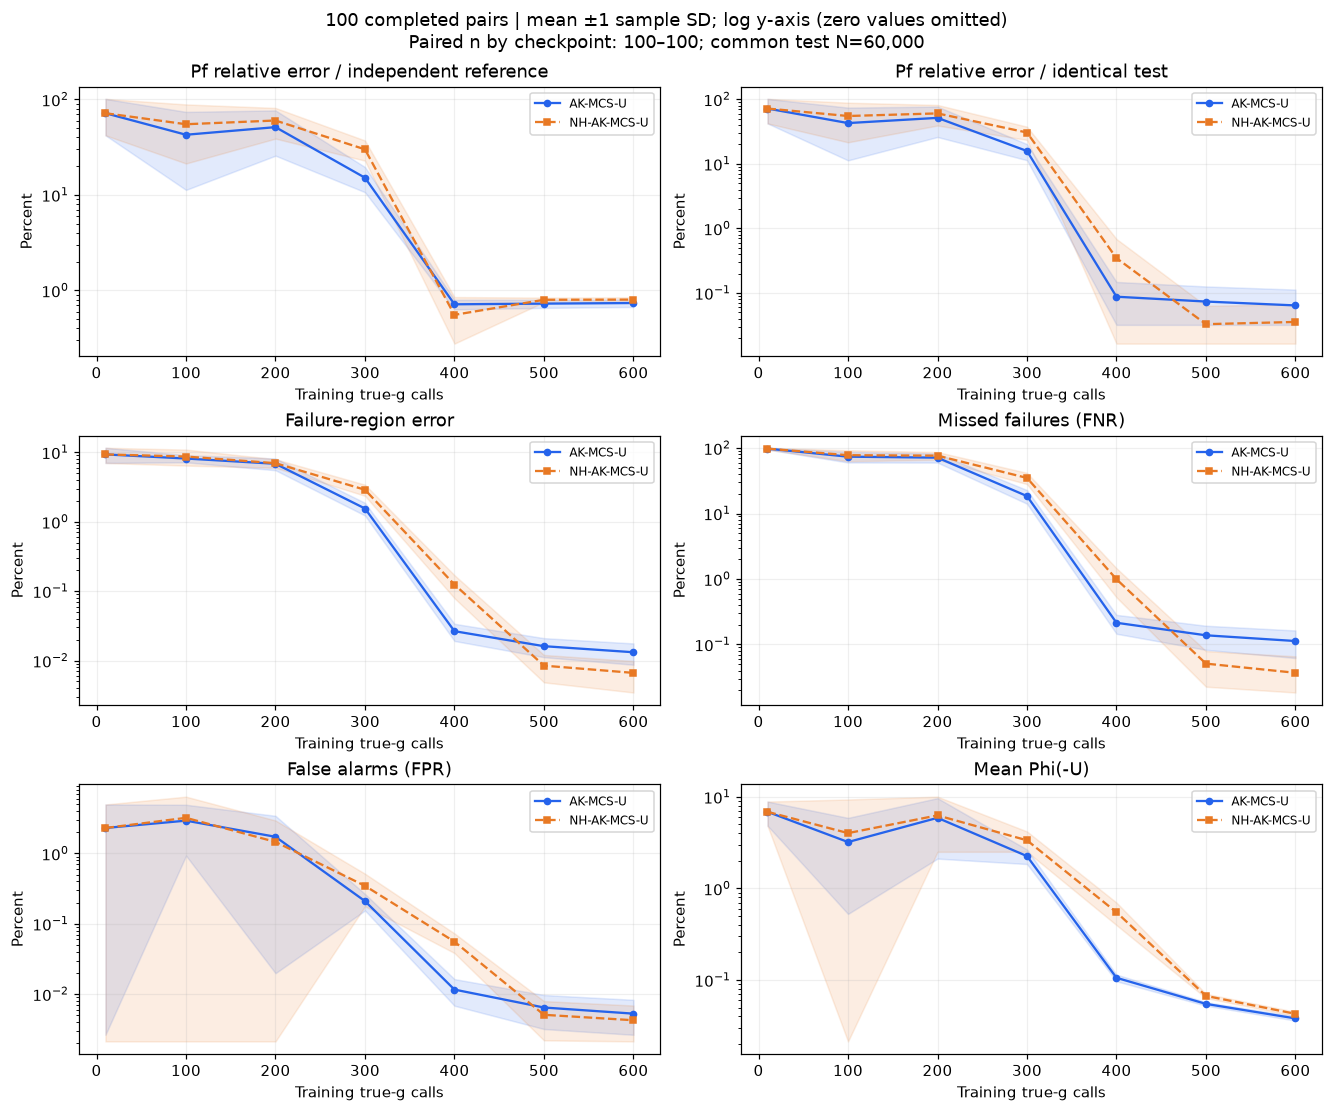

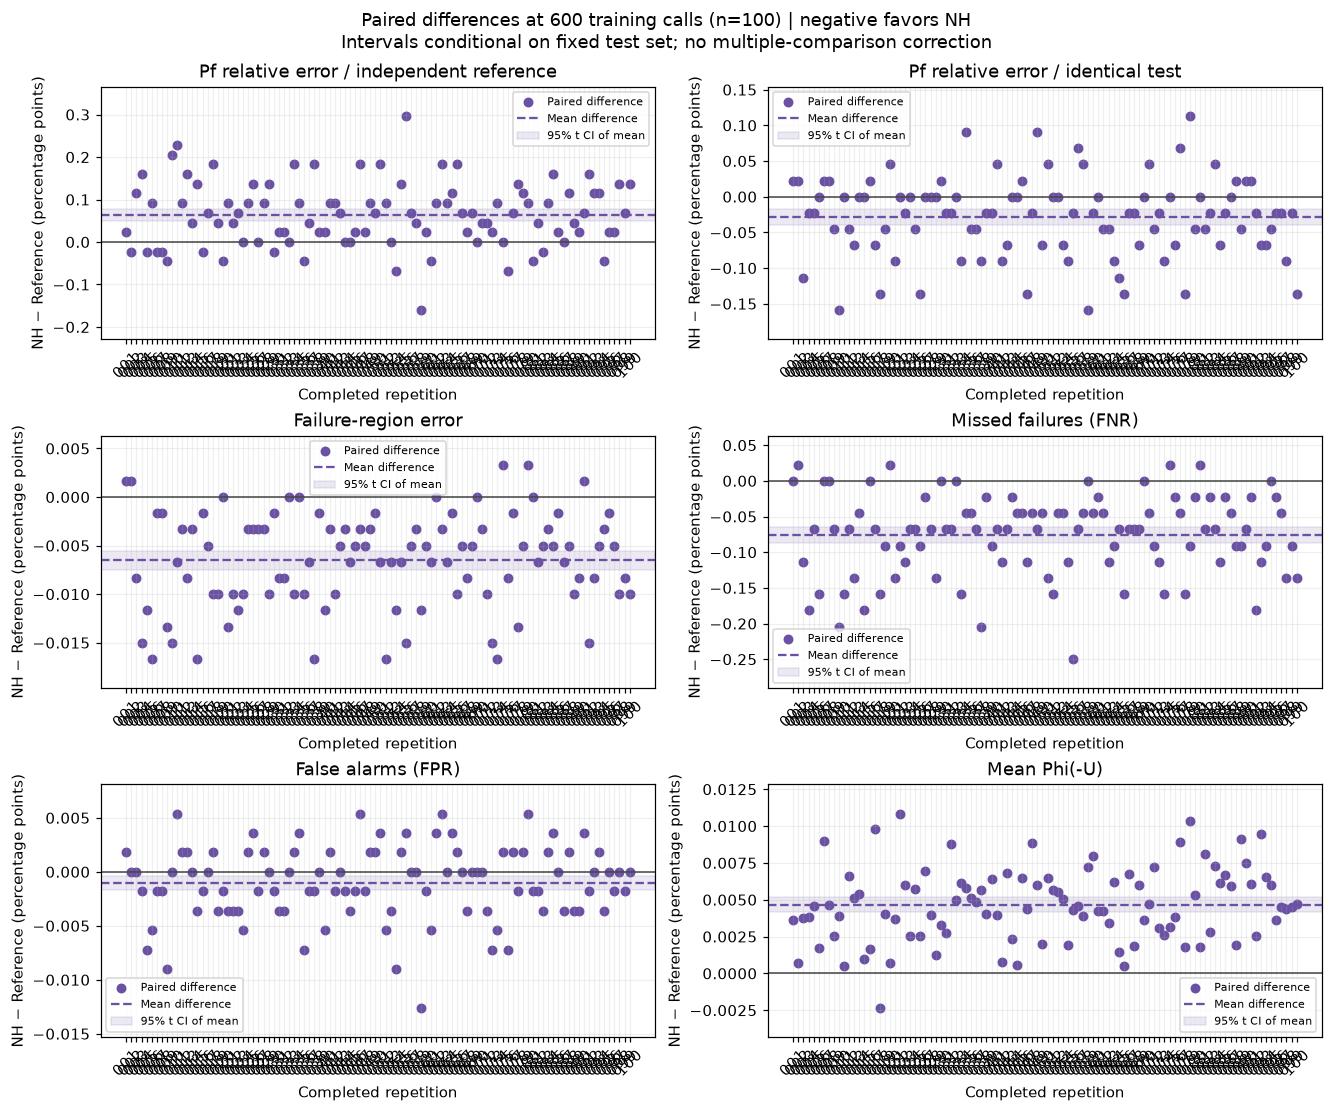

In [79]:
if pairs:
    plt.rcParams.update({"font.size": 10, "figure.dpi": 110})
    fig, axes = plt.subplots(3,2,figsize=(12,10),layout="constrained")
    for ax,(key,title) in zip(axes.flat,METRICS.items()):
        for mode,style in (("reference","-o"),("nh","--s")):
            rows = [r for r in aggregate_rows if r["mode"] == mode and r["metric"] == key]
            x = np.array([r["n_true_calls"] for r in rows])
            y = np.array([100*r["mean"] if r["mean"] is not None else np.nan for r in rows])
            sd = np.array([100*r["sd"] if r["sd"] is not None else np.nan for r in rows])
            ax.plot(x,y,style,color=COLORS[mode],label=MODES[mode],ms=4)
            positive_y = y[np.isfinite(y) & (y > 0)]
            if np.isfinite(sd).any() and positive_y.size:
                valid_band = np.isfinite(y) & np.isfinite(sd) & (y > 0)
                lower = np.maximum(y-sd, positive_y.min()/2)
                ax.fill_between(x,np.where(valid_band,lower,np.nan),
                                np.where(valid_band,y+sd,np.nan),color=COLORS[mode],alpha=.13)
        ax.set(title=title,xlabel="Training true-g calls",ylabel="Percent")
        ax.set_yscale("log")
        ax.grid(alpha=.2)
        ax.legend(fontsize=8)
    pair_counts = [len(eligible_by_checkpoint[n]) for n in checkpoints]
    fig.suptitle(f"{len(pairs)} completed pairs | mean ±1 sample SD; log y-axis (zero values omitted)\n"
                 f"Paired n by checkpoint: {min(pair_counts)}–{max(pair_counts)}; common test N={N_TEST:,}", fontsize=12)
    fig.savefig(ARTIFACT_DIR/"repeated_metric_curves.png",dpi=150,bbox_inches="tight")
    plt.show()
    plt.close(fig)

    fig,axes = plt.subplots(3,2,figsize=(12,10),layout="constrained")
    for ax,(key,title) in zip(axes.flat,METRICS.items()):
        rows = [r for r in paired_rows if r["metric"] == key and r["n_true_calls"] == final_n]
        y = [100*r["difference"] if r["difference"] is not None else np.nan for r in rows]
        ax.scatter(range(1,len(rows)+1),y,c="#6a51a3",s=30,label="Paired difference")
        effect = next(r for r in effect_rows if r["metric"] == key)
        ax.axhline(0,color="#444444",lw=1)
        if effect["mean"] is not None:
            ax.axhline(100*effect["mean"],color="#6a51a3",ls="--",label="Mean difference")
        if effect["ci_low"] is not None:
            ax.axhspan(100*effect["ci_low"],100*effect["ci_high"],color="#6a51a3",alpha=.12,
                       label="95% t CI of mean")
        ax.set(title=title,xlabel="Completed repetition",ylabel="NH − Reference (percentage points)")
        ax.set_xticks(range(1,len(rows)+1),[r["repetition"].removeprefix("rep_") for r in rows],rotation=45)
        ax.grid(alpha=.2)
        ax.legend(fontsize=7)
        differences = [v for v in y if np.isfinite(v)]
        if differences:
            low, high = min(differences), max(differences)
            margin = max((high-low)*.15, max(abs(low),abs(high))*.05, 1e-6)
            ax.set_ylim(low-margin,high+margin)
    fig.suptitle(f"Paired differences at {final_n} training calls (n={len(final_reps)}) | negative favors NH\n"
                 "Intervals conditional on fixed test set; no multiple-comparison correction",fontsize=12)
    fig.savefig(ARTIFACT_DIR/"paired_final_differences.png",dpi=150,bbox_inches="tight")
    plt.show()
    plt.close(fig)


In [80]:
save_json(ARTIFACT_DIR/"repeated_analysis.json",
          {"provenance": provenance, "status": status_rows, "metrics": metric_rows,
           "aggregate": aggregate_rows, "paired_differences": paired_rows, "paired_summary": effect_rows})
if pairs:
    print(f"완료: {len(pairs)} paired 반복 × {len(checkpoints)} 공통 호출 시점. 결과: {ARTIFACT_DIR}")
    for key in ("pf_relative_error_same_set","region_error","failure_miss_rate"):
        r = next(v for v in effect_rows if v["metric"] == key)
        print(f'{METRICS[key]}: NH−Ref 평균={fmt(None if r["mean"] is None else 100*r["mean"],4)} pp; '
              f'NH 승/무/패={r["nh_wins"]}/{r["ties"]}/{r["nh_losses"]}')
    print("실제 오류를 우선 해석하고, 평균 Phi(-U)와 min U는 모델 내부 진단으로 사용하세요.")
else:
    print("완료된 paired 반복이 없습니다. 상태만 저장했습니다.")


완료: 100 paired 반복 × 7 공통 호출 시점. 결과: c:\Users\user\Desktop\LAB\NH-AL\NH-AL\artifacts\analyze\AK-MCS-EFF
Pf relative error / identical test: NH−Ref 평균=-0.0286 pp; NH 승/무/패=60/19/21
Failure-region error: NH−Ref 평균=-0.0065 pp; NH 승/무/패=89/6/5
Missed failures (FNR): NH−Ref 평균=-0.0760 pp; NH 승/무/패=87/9/4
실제 오류를 우선 해석하고, 평균 Phi(-U)와 min U는 모델 내부 진단으로 사용하세요.
